# Лабораторна 10. Завдання 3 — коти-собаки зі скороченим набором

Курс «Глибокі нейронні мережі». Пункти 5–14 умови.

Набір **навмисно малий**: 2000 зображень кожного класу для навчання, по 500 на
клас для перевірки й тестування — разом 6000 замість повних 25 000. На такому
наборі мережа, навчена з нуля, перенавчається майже одразу, тож це найкращий
стенд, щоб побачити, що насправді дають аугментація й перенесення навчання.

| Пункт | Що робиться |
|---|---|
| 5–6 | нарізка набору 2000/500/500 на клас і структура каталогів |
| 7–9 | генератори з аугментацією (і без неї, для контролю) |
| 10 | перенесення навчання з VGG16, порівняння з аугментацією та без |
| 11 | тонке налаштування: розморожування `block5` |
| 12 | інші мережі (InceptionV3, ResNet50) і гіперпараметри |
| 13 | розпізнавання власних зображень, порівняння з ЛР7 і ЛР8 |
| 14 | збереження навчених моделей |

Усі експерименти використовують **той самий вхід 150×150 і той самий
розподіл**, що в лабораторних 7 і 8 — інакше порівняння між лабораторними
було б некоректним.

Середовище, шляхи, перевірка GPU.

In [2]:
import json
import os
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
if IN_COLAB and not tf.config.list_physical_devices('GPU'):
    print('\n!! GPU НЕ УВІМКНЕНО. Середовище виконання -> Змінити тип -> ГП T4.')

LAB_ROOT = Path('/content') if IN_COLAB else Path.cwd().parent
RESULTS = LAB_ROOT / 'results'
(RESULTS / 'raw').mkdir(parents=True, exist_ok=True)

SEED = 42
INPUT_SIZE = 150          # той самий вхід, що в ЛР7 і ЛР8 — щоб порівняння було чесним
BATCH = 32
tf.keras.utils.set_random_seed(SEED)
print('Результати:', RESULTS)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Результати: /content/results


**Пункти 5–6.** Скорочений набір і структура каталогів.

`flow_from_directory` визначає клас за назвою теки, тому структура
`<набір>/<клас>/<файли>` — це не прикраса, а вимога API.

In [4]:
# Пункти 5-6: обмежений набір 2000/500/500 на клас.
#
# Його нарізає scripts/prepare_cats_dogs_2000.py з повного Kaggle Dogs vs Cats
# за діапазонами індексів у імені файлу: 0-1999 навчальні, 2000-2499
# перевірочні, 2500-2999 тестові. Діапазони не перетинаються, тож тестові
# зображення мережа не бачить ніколи.
DATA_DIR = Path('/content/cats_dogs_small') if IN_COLAB \
    else LAB_ROOT / 'data' / 'cats_dogs_small'

if IN_COLAB and not DATA_DIR.exists():
    from google.colab import drive

    drive.mount('/content/drive')
    src = Path('/content/drive/MyDrive/dl_lab10/cats_dogs_small.zip')
    if not src.exists():
        raise FileNotFoundError(
            f'немає {src} — залийте cats_dogs_small.zip у MyDrive/dl_lab10/')
    with zipfile.ZipFile(src) as z:
        z.extractall(DATA_DIR)

TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'validation'
TEST_DIR = DATA_DIR / 'test'

total = 0
print(f"{'набір':<12} {'котів':>7} {'собак':>7} {'разом':>7}")
print('-' * 38)
for _name, _d in (('train', TRAIN_DIR), ('validation', VAL_DIR), ('test', TEST_DIR)):
    _c = len(list((_d / 'cats').glob('*.jpg')))
    _g = len(list((_d / 'dogs').glob('*.jpg')))
    total += _c + _g
    print(f'{_name:<12} {_c:>7} {_g:>7} {_c + _g:>7}')
print('-' * 38)
print(f"{'РАЗОМ':<12} {'':>7} {'':>7} {total:>7}")
assert total == 6000, f'очікувалось 6000 зображень, отримано {total}'


Mounted at /content/drive
набір          котів   собак   разом
--------------------------------------
train           2000    2000    4000
validation       500     500    1000
test             500     500    1000
--------------------------------------
РАЗОМ                           6000


**Пункти 7–9.** Генератори для навчання, перевірки й тестування.

In [5]:
# Пункти 7-9: генератори.
#
# Аугментація застосовується ЛИШЕ до навчального набору. Перевірочний і
# тестовий тільки нормалізуються — інакше їхні оцінки перестануть бути
# чесною мірою якості.
#
# Друга тонкість: у кожної попередньо навченої мережі своя препроцесія входу
# (VGG16 віднімає середнє ImageNet, InceptionV3 масштабує в [-1, 1]).
# Якщо підставити звичне rescale=1./255, мережа отримає розподіл, на якому її
# не вчили, і точність тихо просяде без жодної помилки в коді.
AUG_PARAMS = dict(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2,
                  shear_range=0.2, zoom_range=0.2, horizontal_flip=True,
                  fill_mode='nearest')


def make_generators(augment, preprocess=None, size=INPUT_SIZE, aug_params=None):
    common = dict(preprocessing_function=preprocess) if preprocess \
        else dict(rescale=1./255)
    params = AUG_PARAMS if aug_params is None else aug_params
    train_datagen = ImageDataGenerator(**common, **(params if augment else {}))
    plain_datagen = ImageDataGenerator(**common)

    train = train_datagen.flow_from_directory(
        TRAIN_DIR, target_size=(size, size), batch_size=BATCH, class_mode='binary')
    val = plain_datagen.flow_from_directory(
        VAL_DIR, target_size=(size, size), batch_size=BATCH, class_mode='binary')
    test = plain_datagen.flow_from_directory(
        TEST_DIR, target_size=(size, size), batch_size=BATCH, class_mode='binary',
        shuffle=False)
    return train, val, test


_t, _v, _te = make_generators(augment=True)
print('\nкласи:', _t.class_indices)

Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.

класи: {'cats': 0, 'dogs': 1}


Як саме аугментація змінює зображення.

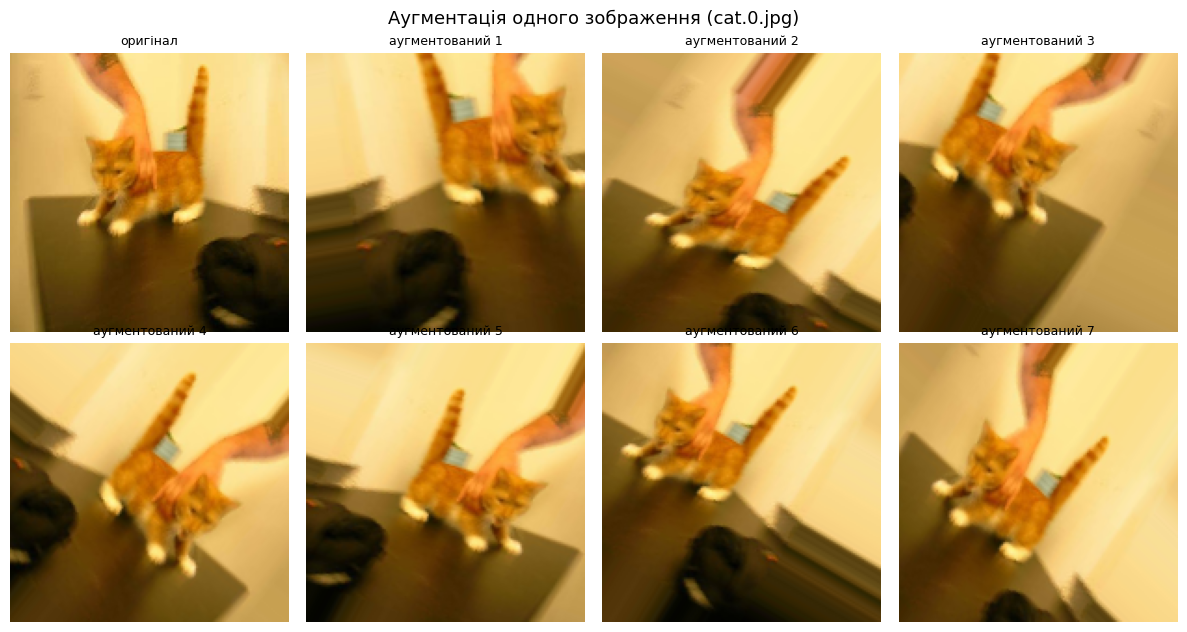

In [6]:
# Що саме робить аугментація: одне зображення вісім разів.
sample_path = sorted((TRAIN_DIR / 'cats').glob('*.jpg'))[0]
_img = img_to_array(load_img(sample_path, target_size=(INPUT_SIZE, INPUT_SIZE)))
_gen = ImageDataGenerator(rescale=1./255, **AUG_PARAMS)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
_flow = _gen.flow(np.expand_dims(_img, 0), batch_size=1, seed=SEED)
for _i, _ax in enumerate(axes.ravel()):
    _ax.imshow(_img / 255.0 if _i == 0 else next(_flow)[0])
    _ax.set_title('оригінал' if _i == 0 else f'аугментований {_i}', fontsize=9)
    _ax.axis('off')
fig.suptitle(f'Аугментація одного зображення ({sample_path.name})', fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS / 'task3_augmentation_examples.png', dpi=110, bbox_inches='tight')
plt.show()

**Пункти 10–12.** Стенд експериментів.

Одна функція `run()` на всі прогони: так між експериментами гарантовано
відрізняється лише те, що досліджується, а не випадкові дрібниці в коді.
`EarlyStopping` з `restore_best_weights` повертає ваги найкращої епохи, тому
пізнє перенавчання не псує підсумкову оцінку.

In [7]:
# Пункт 10: перенесення навчання. Базова мережа — параметр, щоб пункт 12
# (інші попередньо навчені моделі) не вимагав копіювати код.
from tensorflow.keras.applications import inception_v3, resnet50, vgg16

BASES = {
    'VGG16': {'ctor': vgg16.VGG16, 'preprocess': vgg16.preprocess_input,
              'unfreeze_from': 'block5_conv1'},
    'InceptionV3': {'ctor': inception_v3.InceptionV3,
                    'preprocess': inception_v3.preprocess_input,
                    'unfreeze_from': 'mixed8'},
    'ResNet50': {'ctor': resnet50.ResNet50, 'preprocess': resnet50.preprocess_input,
                 'unfreeze_from': 'conv5_block1_1_conv'},
}

results, models = {}, {}


def build_model(base_name, dropout=0.5, dense=256, learning_rate=1e-4,
                optimizer='rmsprop', unfreeze=False, size=INPUT_SIZE):
    """Згорткова база + голова GlobalAveragePooling / Dense / Dropout / sigmoid.

    unfreeze=True розморожує верхній згортковий блок бази (пункт 11).
    BatchNormalization лишається замороженим завжди: його ковзні середні взяті
    з ImageNet і на 4000 зображеннях перенавчаються в шум.
    """
    spec = BASES[base_name]
    base = spec['ctor'](weights='imagenet', include_top=False,
                        input_shape=(size, size, 3))
    base.trainable = False

    unfrozen = []
    if unfreeze:
        names = [l.name for l in base.layers]
        start = names.index(spec['unfreeze_from'])
        for layer in base.layers[start:]:
            if isinstance(layer, layers.BatchNormalization):
                continue
            layer.trainable = True
            unfrozen.append(layer.name)

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dense(dense, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = Model(base.input, out)

    opt = (RMSprop if optimizer == 'rmsprop' else Adam)(learning_rate=learning_rate)
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return model, spec['preprocess'], unfrozen


def run(name, title, base_name, augment=True, epochs=15, patience=4,
        aug_params=None, **kwargs):
    """Один експеримент: навчання, рання зупинка, оцінка на тестовому наборі."""
    print('\n' + '=' * 74)
    print(title)
    print('=' * 74)
    tf.keras.utils.set_random_seed(SEED)

    model, preprocess, unfrozen = build_model(base_name, **kwargs)
    train, val, test = make_generators(augment, preprocess,
                                       size=kwargs.get('size', INPUT_SIZE),
                                       aug_params=aug_params)

    n_total = int(model.count_params())
    n_train = int(sum(w.shape.num_elements() for w in model.trainable_weights))
    print(f'параметрів {n_total:,}, навчаних {n_train:,}, '
          f'розморожено шарів бази {len(unfrozen)}')

    cb = [tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=patience,
                                           restore_best_weights=True, verbose=1)]
    t0 = time.time()
    hist = model.fit(train, validation_data=val, epochs=epochs, verbose=2, callbacks=cb)
    elapsed = time.time() - t0

    test_loss, test_acc = model.evaluate(test, verbose=0)
    acc, val_acc = hist.history['accuracy'], hist.history['val_accuracy']
    print(f'\nтест: accuracy {test_acc:.4f}, loss {test_loss:.4f}, '
          f'час {elapsed / 60:.1f} хв')

    results[name] = {
        'name': name, 'title': title, 'base': base_name, 'augment': augment,
        'fine_tuned': bool(unfrozen), 'unfrozen_layers': len(unfrozen),
        'params': {'total': n_total, 'trainable': n_train},
        'hyper': {k: str(v) for k, v in kwargs.items()},
        'epochs_run': len(acc),
        'final_train_accuracy': float(acc[-1]),
        'final_val_accuracy': float(val_acc[-1]),
        'best_val_accuracy': float(max(val_acc)),
        'overfit_gap': float(acc[-1] - val_acc[-1]),
        'test_accuracy': float(test_acc), 'test_loss': float(test_loss),
        'train_time_sec': round(elapsed, 1),
        'history': {k: [float(x) for x in v] for k, v in hist.history.items()},
    }

    # Модель одразу зберігаємо на диск і звільняємо пам'ять. Інакше всі вісім
    # моделей разом зі станом оптимізатора лежали б у пам'яті GPU одночасно,
    # і довгий прогін міг би впасти на останніх експериментах.
    path = RESULTS / f'task3_{name}.keras'
    model.save(path)
    models[name] = {'path': str(path), 'preprocess': preprocess}
    print(f'збережено {path.name}, {path.stat().st_size / 1e6:.0f} МБ')

    del model
    tf.keras.backend.clear_session()

**Пункти 10–11.** Аугментація і донавчання на VGG16.

In [8]:
# Пункти 10-11. Кожен наступний прогін змінює рівно один чинник відносно
# попереднього — інакше різницю в результатах не було б чому приписати.

run('vgg16_noaug', 'VGG16, заморожена база, БЕЗ аугментації', 'VGG16', augment=False)
run('vgg16_aug', 'VGG16, заморожена база, З аугментацією', 'VGG16', augment=True)
run('vgg16_aug_ft', 'VGG16, аугментація + донавчання block5', 'VGG16',
    augment=True, unfreeze=True, learning_rate=1e-5, epochs=12)

print('\n\nПроміжний підсумок:')
for _k in ('vgg16_noaug', 'vgg16_aug', 'vgg16_aug_ft'):
    _r = results[_k]
    print(f"  {_r['title']:<48} тест {_r['test_accuracy']:.4f}  "
          f"розрив {_r['overfit_gap']:+.3f}")


VGG16, заморожена база, БЕЗ аугментації
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
параметрів 14,846,273, навчаних 131,585, розморожено шарів бази 0
Epoch 1/15
125/125 - 25s - 197ms/step - accuracy: 0.8120 - loss: 1.5284 - val_accuracy: 0.9490 - val_loss: 0.2200
Epoch 2/15
125/125 - 8s - 66ms/step - accuracy: 0.9170 - loss: 0.5680 - val_accuracy: 0.9590 - val_loss: 0.2042
Epoch 3/15
125/125 - 8s - 66ms/step - accuracy: 0.9398 - loss: 0.3687 - val_accuracy: 0.9650 - val_loss: 0.1882
Epoch 4/15
125/125 - 9s - 69ms/step - accuracy: 0.9492 - loss: 0.3296 - val_accuracy: 0.9670 - val_loss: 0.1882
Epoch 5/15
125/125 - 8s - 67ms/step - accuracy: 0.9473 - loss: 0.3001 - val_accuracy: 0.9680 - val_loss: 0.1879
Epoch 6/15
125/125 - 9s - 71ms/step - accuracy: 0.9580 - loss: 0.2150 - val_accuracy: 0.9640 - val_loss: 0.1826
Epoch 7/15
125/125 - 9s - 69ms/step - accu

**Пункт 12.** Інші мережі й гіперпараметри.

Перебираються не всі комбінації підряд, а ті, що показали себе в ЛР8 —
саме цього вимагає умова («використовуйте ваші напрацювання з попередніх
робіт, щоб зменшити кількість експериментів»).

In [9]:
# Пункт 12: інші попередньо навчені мережі та гіперпараметри.
#
# Комбінації взяті з напрацювань ЛР8, щоб не перебирати все підряд: там на
# повному наборі InceptionV3 і ResNet50 дали найвищу точність, Dropout 0.5
# найкраще стримував перенавчання, а RMSprop був стабільнішим за Adam на
# замороженій базі.
run('inception_aug_ft', 'InceptionV3, аугментація + донавчання mixed8',
    'InceptionV3', augment=True, unfreeze=True, learning_rate=1e-5, epochs=12)
run('resnet50_aug_ft', 'ResNet50, аугментація + донавчання conv5',
    'ResNet50', augment=True, unfreeze=True, learning_rate=1e-5, epochs=12)

best_base = max(BASES, key=lambda b: max(
    (r['test_accuracy'] for r in results.values() if r['base'] == b), default=0))
print(f'\n\nНайкраща основа поки що: {best_base}')

# Слабша аугментація: чи не задужі спотворення на 4000 зображеннях.
SOFT_AUG = dict(rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
                zoom_range=0.1, horizontal_flip=True, fill_mode='nearest')

run('best_soft_aug', f'{best_base}, слабша аугментація + донавчання',
    best_base, augment=True, unfreeze=True, learning_rate=1e-5, epochs=12,
    aug_params=SOFT_AUG)
run('best_adam', f'{best_base}, донавчання, Adam замість RMSprop',
    best_base, augment=True, unfreeze=True, optimizer='adam',
    learning_rate=1e-5, epochs=12)
run('best_dropout03', f'{best_base}, донавчання, Dropout 0.3 замість 0.5',
    best_base, augment=True, unfreeze=True, dropout=0.3,
    learning_rate=1e-5, epochs=12)


InceptionV3, аугментація + донавчання mixed8
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
параметрів 22,327,585, навчаних 11,633,153, розморожено шарів бази 45
Epoch 1/12
125/125 - 74s - 588ms/step - accuracy: 0.8610 - loss: 0.3595 - val_accuracy: 0.9690 - val_loss: 0.0923
Epoch 2/12
125/125 - 25s - 200ms/step - accuracy: 0.9273 - loss: 0.1906 - val_accuracy: 0.9720 - val_loss: 0.0863
Epoch 3/12
125/125 - 26s - 210ms/step - accuracy: 0.9405 - loss: 0.1585 - val_accuracy: 0.9690 - val_loss: 0.0911
Epoch 4/12
125/125 - 27s - 213ms/step - accuracy: 0.9442 - loss: 0.1416 - val_accuracy: 0.9710 - val_loss: 0.0840
Epoch 5/12
125/125 - 26s - 212ms/step - accuracy: 0.9467 - loss: 0.1330 - val_accuracy: 0.9600 - val_loss: 0.0997
Epoch 6/12
125/125 - 26s - 207ms/step - accuracy: 0.9528 - loss: 0.1147 - val_accuracy: 0.9720 - val_loss: 0.0773
Epoch 6: early stopping

Криві навчання всіх експериментів.

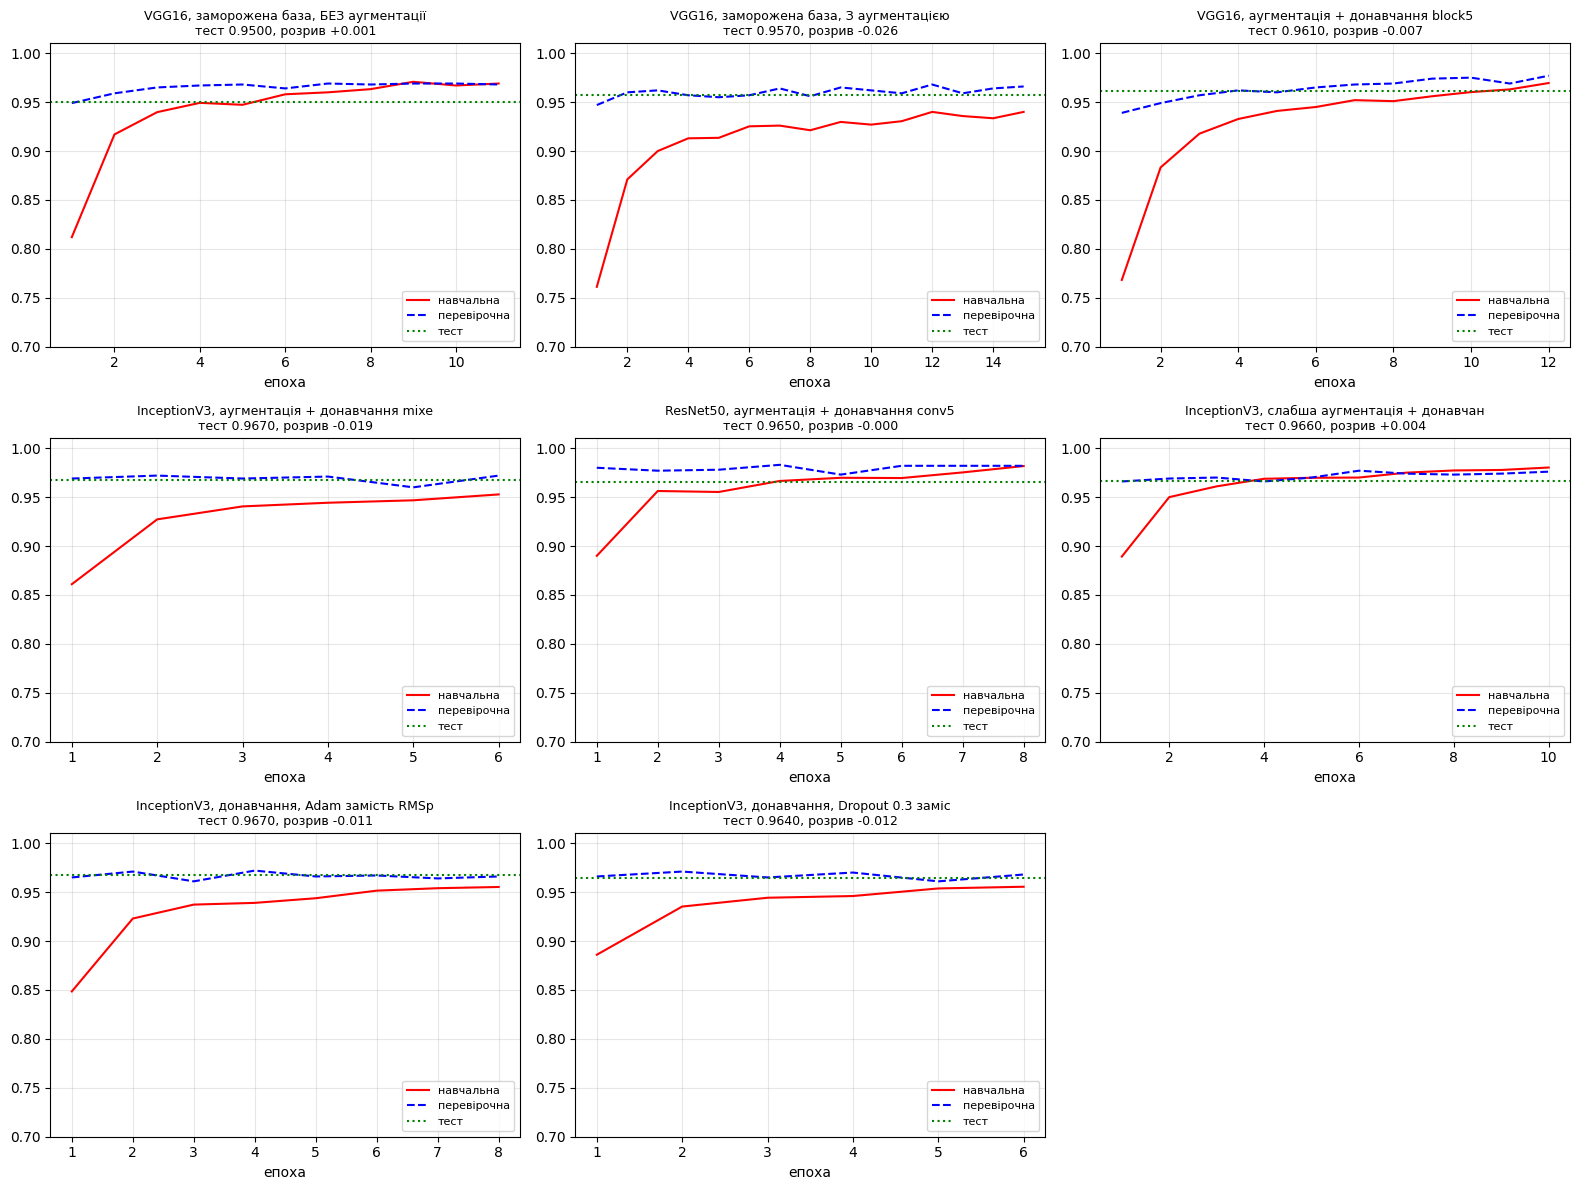

In [10]:
# Криві навчання всіх експериментів.
_n = len(results)
_cols = 3
_rows = (_n + _cols - 1) // _cols
fig, axes = plt.subplots(_rows, _cols, figsize=(5.3 * _cols, 4.0 * _rows))
_flat = np.atleast_1d(axes).ravel()
for _ax, _r in zip(_flat, results.values()):
    _h = _r['history']
    _ep = range(1, len(_h['accuracy']) + 1)
    _ax.plot(_ep, _h['accuracy'], 'r-', label='навчальна')
    _ax.plot(_ep, _h['val_accuracy'], 'b--', label='перевірочна')
    _ax.axhline(_r['test_accuracy'], color='green', ls=':', label='тест')
    _ax.set_title(f"{_r['title'][:42]}\nтест {_r['test_accuracy']:.4f}, "
                  f"розрив {_r['overfit_gap']:+.3f}", fontsize=9)
    _ax.set_xlabel('епоха')
    _ax.set_ylim(0.7, 1.01)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=8, loc='lower right')
for _ax in _flat[_n:]:
    _ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTS / 'task3_histories.png', dpi=110, bbox_inches='tight')
plt.show()

**Пункт 13.** Зведена таблиця й відповіді на питання умови.

In [11]:
# Пункт 13: зведена таблиця експериментів.
_cols = [('експеримент', lambda r: r['title'][:44]),
         ('аугм.', lambda r: 'так' if r['augment'] else 'ні'),
         ('донавч.', lambda r: 'так' if r['fine_tuned'] else 'ні'),
         ('навчаних', lambda r: f"{r['params']['trainable']:,}"),
         ('епох', lambda r: str(r['epochs_run'])),
         ('val', lambda r: f"{r['best_val_accuracy']:.4f}"),
         ('тест', lambda r: f"{r['test_accuracy']:.4f}"),
         ('розрив', lambda r: f"{r['overfit_gap']:+.3f}"),
         ('хв', lambda r: f"{r['train_time_sec'] / 60:.1f}")]

_rows = [[f(r) for _, f in _cols] for r in results.values()]
_w = [max(len(h), *(len(row[i]) for row in _rows)) for i, (h, _) in enumerate(_cols)]
print(' | '.join(h.ljust(x) for (h, _), x in zip(_cols, _w)))
print('-+-'.join('-' * x for x in _w))
for _row in _rows:
    print(' | '.join(c.ljust(x) for c, x in zip(_row, _w)))

_a, _b = results['vgg16_noaug'], results['vgg16_aug']
_c = results['vgg16_aug_ft']
print(f"\nпункт 10, аугментація: тест {_a['test_accuracy']:.4f} -> "
      f"{_b['test_accuracy']:.4f} ({_b['test_accuracy'] - _a['test_accuracy']:+.4f}), "
      f"розрив {_a['overfit_gap']:+.3f} -> {_b['overfit_gap']:+.3f}")
print(f"пункт 11, донавчання:  тест {_b['test_accuracy']:.4f} -> "
      f"{_c['test_accuracy']:.4f} ({_c['test_accuracy'] - _b['test_accuracy']:+.4f})")

BEST_NAME = max(results, key=lambda k: results[k]['test_accuracy'])
BEST = results[BEST_NAME]
print(f"\nНайкраща модель: {BEST['title']} — тест {BEST['test_accuracy']:.4f}")

експеримент                                  | аугм. | донавч. | навчаних   | епох | val    | тест   | розрив | хв 
---------------------------------------------+-------+---------+------------+------+--------+--------+--------+----
VGG16, заморожена база, БЕЗ аугментації      | ні    | ні      | 131,585    | 11   | 0.9690 | 0.9500 | +0.001 | 1.8
VGG16, заморожена база, З аугментацією       | так   | ні      | 131,585    | 15   | 0.9680 | 0.9570 | -0.026 | 6.5
VGG16, аугментація + донавчання block5       | так   | так     | 7,211,009  | 12   | 0.9770 | 0.9610 | -0.007 | 5.2
InceptionV3, аугментація + донавчання mixed8 | так   | так     | 11,633,153 | 6    | 0.9720 | 0.9670 | -0.019 | 3.4
ResNet50, аугментація + донавчання conv5     | так   | так     | 15,478,273 | 8    | 0.9830 | 0.9650 | -0.000 | 3.9
InceptionV3, слабша аугментація + донавчання | так   | так     | 11,633,153 | 10   | 0.9770 | 0.9660 | +0.004 | 4.7
InceptionV3, донавчання, Adam замість RMSpro | так   | так     | 11,633,

**Пункти 10 і 13.** Власні зображення — ті самі, що в ЛР7 і ЛР8.

In [12]:
# Пункти 10 і 13: ті самі власні зображення, що в ЛР7 і ЛР8.
#
#   cats_dogs         20 звичайних фото
#   cats_dogs_hard    10 складних (тварина дрібна, у траві, напівсхована)
#   cats_dogs_cropped  6 обрізаних версій складних
MY_IMAGES = Path('/content/my_images') if IN_COLAB else LAB_ROOT / 'my_images'
if IN_COLAB and not MY_IMAGES.exists():
    from google.colab import drive

    drive.mount('/content/drive')
    _src = Path('/content/drive/MyDrive/dl_lab10/my_images.zip')
    if not _src.exists():
        raise FileNotFoundError(f'немає {_src} — залийте my_images.zip у MyDrive/dl_lab10/')
    with zipfile.ZipFile(_src) as z:
        z.extractall(MY_IMAGES)

FOLDERS = {'cats_dogs': '20 звичайних', 'cats_dogs_hard': '10 складних',
           'cats_dogs_cropped': '6 обрізаних'}


def predict_folder(model, preprocess, folder, size=INPUT_SIZE):
    """Клас із префікса імені файлу: cat_* -> кіт, dog_* -> собака.
    class_indices {'cats': 0, 'dogs': 1}, тож sigmoid > 0.5 означає «собака».
    До власних зображень іде та сама препроцесія, що до навчального набору."""
    paths = sorted(p for p in folder.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if not paths:
        raise FileNotFoundError(f'у {folder} немає зображень')
    batch = np.vstack([
        np.expand_dims(preprocess(img_to_array(load_img(p, target_size=(size, size)))), 0)
        for p in paths
    ])
    probs = model.predict(batch, verbose=0).ravel()
    out = []
    for p, prob in zip(paths, probs):
        actual = 0 if p.stem.lower().startswith('cat') else 1
        pred = int(prob > 0.5)
        out.append({'file': p.name, 'prob_dog': float(prob),
                    'predicted': 'собака' if pred else 'кіт',
                    'actual': 'собака' if actual else 'кіт',
                    'correct': pred == actual})
    return out


# Найкращу модель завантажуємо назад з диска — у пам'яті її вже немає.
best_model = tf.keras.models.load_model(models[BEST_NAME]['path'])
best_preprocess = models[BEST_NAME]['preprocess']
own = {}
print(f"Найкраща модель: {BEST['title']}\n")
for folder, label in FOLDERS.items():
    recs = predict_folder(best_model, best_preprocess, MY_IMAGES / folder)
    own[folder] = recs
    good = sum(r['correct'] for r in recs)
    print(f'{label:<16} {good} з {len(recs)}')
    for r in recs:
        if not r['correct']:
            print(f"    помилка: {r['file']:<34} P(собака)={r['prob_dog']:.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Найкраща модель: InceptionV3, аугментація + донавчання mixed8

20 звичайних     16 з 20
    помилка: cat_08.jpg                         P(собака)=0.561
    помилка: cat_09.jpg                         P(собака)=0.589
    помилка: cat_10.jpg                         P(собака)=0.607
    помилка: dog_10.jpg                         P(собака)=0.351
10 складних      4 з 10
    помилка: cat_hard_bushes.jpg                P(собака)=0.767
    помилка: cat_hard_flowers.jpg               P(собака)=0.877
    помилка: cat_hard_garden.jpg                P(собака)=0.844
    помилка: cat_hard_park.jpg                  P(собака)=0.515
    помилка: cat_hard_tree.jpg                  P(собака)=0.670
    помилка: dog_hard_grass.jpg                 P(собака)=0.464
6 обрізаних      2 з 6
    помилка: crop_cat_hard_bushes.jpg           P(собака)=0.098
    помилка: crop_cat_hard_flowe

Сітка всіх власних зображень із прогнозами найкращої моделі.

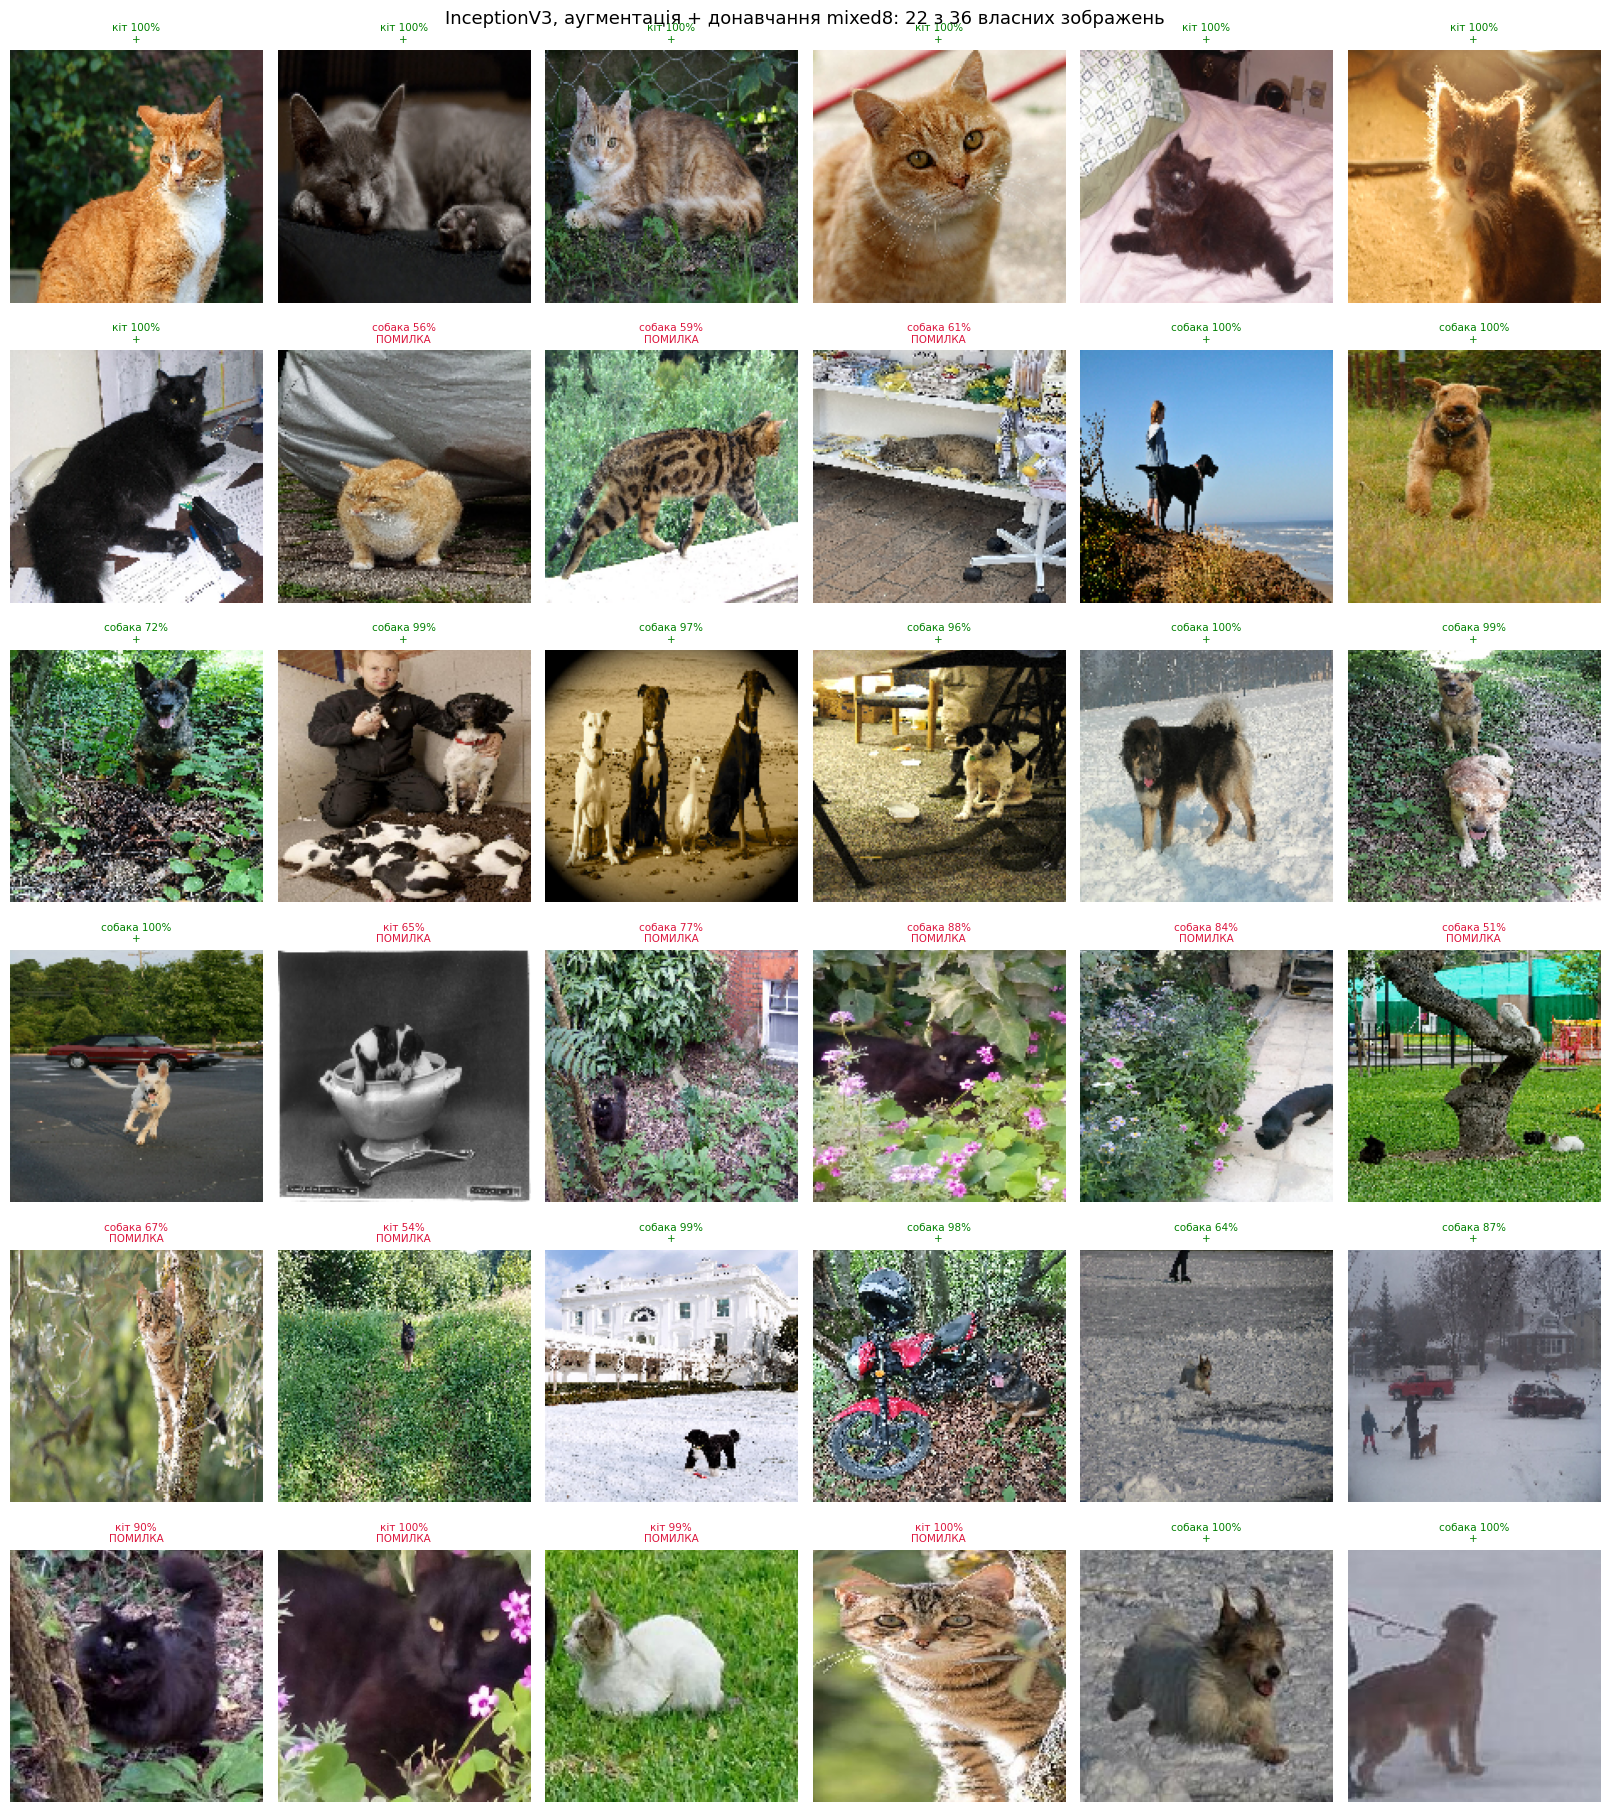

In [13]:
# Сітка з усіма власними зображеннями найкращої моделі.
_all = [(folder, r) for folder, recs in own.items() for r in recs]
_cols = 6
_rows = (len(_all) + _cols - 1) // _cols
fig, axes = plt.subplots(_rows, _cols, figsize=(2.7 * _cols, 3.1 * _rows))
for _ax, (_folder, _r) in zip(np.atleast_1d(axes).ravel(), _all):
    _conf = _r['prob_dog'] if _r['predicted'] == 'собака' else 1 - _r['prob_dog']
    _ax.imshow(load_img(MY_IMAGES / _folder / _r['file'],
                        target_size=(INPUT_SIZE, INPUT_SIZE)))
    _ax.set_title(f"{_r['predicted']} {_conf:.0%}\n{'+' if _r['correct'] else 'ПОМИЛКА'}",
                  fontsize=7.5, color='green' if _r['correct'] else 'crimson')
    _ax.axis('off')
for _ax in np.atleast_1d(axes).ravel()[len(_all):]:
    _ax.axis('off')
_good = sum(r['correct'] for _, r in _all)
fig.suptitle(f"{BEST['title']}: {_good} з {len(_all)} власних зображень", fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS / 'task3_own_images.png', dpi=110, bbox_inches='tight')
plt.show()

**Пункт 13.** Порівняння з попередніми лабораторними.

Головне питання: чи може перенесення навчання з аугментацією на наборі в
шість разів меншому обігнати мережу, навчену з нуля на повних 25 000?

In [14]:
# Пункт 13: порівняння з попередніми лабораторними на тих самих зображеннях.
#
# ЛР7 — своя CNN з нуля на повному наборі 25 000 (17500/3750/3750).
# ЛР8 — перенесення навчання на тому самому повному наборі.
# ЛР10 — перенесення навчання + аугментація на скороченому наборі 4000/1000/1000.
#
# Головне, що тут видно: скорочений набір у шість разів менший, але
# перенесення навчання з аугментацією все одно обганяє мережу з нуля,
# навчену на повних 25 000.
LAB7 = {'name': 'ЛР7: своя CNN з нуля, 25 000 зображень',
        'test_accuracy': 0.8424, 'params': 1_212_513,
        'own': (16, 20), 'hard': (4, 10), 'cropped': (2, 6)}

print(f"{'модель':<52} {'тест':>8} {'звич.':>8} {'складні':>9} {'обріз.':>8}")
print('-' * 90)
print(f"{LAB7['name']:<52} {LAB7['test_accuracy']:>8.4f} "
      f"{LAB7['own'][0]}/{LAB7['own'][1]:<6} {LAB7['hard'][0]}/{LAB7['hard'][1]:<7} "
      f"{LAB7['cropped'][0]}/{LAB7['cropped'][1]:<6}")

_o = sum(r['correct'] for r in own['cats_dogs'])
_h = sum(r['correct'] for r in own['cats_dogs_hard'])
_cr = sum(r['correct'] for r in own['cats_dogs_cropped'])
print(f"{'ЛР10: ' + BEST['title']:<52} {BEST['test_accuracy']:>8.4f} "
      f"{_o}/{len(own['cats_dogs']):<6} {_h}/{len(own['cats_dogs_hard']):<7} "
      f"{_cr}/{len(own['cats_dogs_cropped']):<6}")

_diff = BEST['test_accuracy'] - LAB7['test_accuracy']
_word = 'вище' if _diff > 0 else 'нижче'
print(f"\nРізниця з ЛР7: {_diff:+.4f} на тестовому наборі — тобто {_word}, "
      f"і це при навчальному наборі в 4.4 раза меншому "
      f"(4000 зображень проти 17500).")
if _diff > 0:
    print('Перенесення навчання з аугментацією перекриває брак даних: мережа')
    print('не вчить ознаки з нуля, а бере готові з ImageNet, тож їй вистачає')
    print('у рази меншої вибірки, щоб навчити лише класифікатор поверх них.')
else:
    print('Якщо різниця від`ємна — перевірте, чи всі епохи відпрацювали і чи')
    print('не зупинив EarlyStopping навчання зарано.')
print('ЛР8 (перенесення навчання на повному наборі): числа в dl/lab8/results/,')
print('порівняння з ними — у звіті README.')

модель                                                   тест    звич.   складні   обріз.
------------------------------------------------------------------------------------------
ЛР7: своя CNN з нуля, 25 000 зображень                 0.8424 16/20     4/10      2/6     
ЛР10: InceptionV3, аугментація + донавчання mixed8     0.9670 16/20     4/10      2/6     

Різниця з ЛР7: +0.1246 на тестовому наборі — тобто вище, і це при навчальному наборі в 4.4 раза меншому (4000 зображень проти 17500).
Перенесення навчання з аугментацією перекриває брак даних: мережа
не вчить ознаки з нуля, а бере готові з ImageNet, тож їй вистачає
у рази меншої вибірки, щоб навчити лише класифікатор поверх них.
ЛР8 (перенесення навчання на повному наборі): числа в dl/lab8/results/,
порівняння з ними — у звіті README.


**Пункт 14.** Збереження моделей і експорт результатів.

Зіп покласти у `dl/lab10/results/incoming/`, ноутбук — через
**Файл → Завантажити → Завантажити .ipynb** у `dl/lab10/notebooks/`.

In [15]:
# Пункт 14: збереження моделей і експорт чисел.
metrics = {
    'task': 'task3_cats_dogs_small',
    'seed': SEED, 'input_size': INPUT_SIZE, 'tensorflow': tf.__version__,
    'dataset': {'train_per_class': 2000, 'val_per_class': 500, 'test_per_class': 500},
    'experiments': results,
    'best': BEST_NAME,
    'own_images': own,
    'own_summary': {k: [sum(r['correct'] for r in v), len(v)] for k, v in own.items()},
    'lab7_baseline': LAB7,
}
out = RESULTS / 'raw' / 'task3.json'
out.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Збережено', out, f'{out.stat().st_size / 1024:.0f} КБ')

# Моделі вже збережено під час навчання. На Drive копіюємо не всі вісім
# (це були б гігабайти), а найкращу загалом і найкращу для кожної основи —
# решта відрізняється лише гіперпараметрами, а їхні числа є в JSON.
_keep = {BEST_NAME}
for _b in BASES:
    _cands = [k for k, r in results.items() if r['base'] == _b]
    if _cands:
        _keep.add(max(_cands, key=lambda k: results[k]['test_accuracy']))

print('моделі для здачі:')
for _name in sorted(_keep):
    _p = Path(models[_name]['path'])
    print(f'  {_p.name} — {_p.stat().st_size / 1e6:.1f} МБ')

if IN_COLAB:
    _drive = Path('/content/drive/MyDrive/dl_lab10')
    (_drive / 'models').mkdir(parents=True, exist_ok=True)
    (_drive / 'results').mkdir(parents=True, exist_ok=True)
    for _name in sorted(_keep):
        _p = Path(models[_name]['path'])
        shutil.copy(_p, _drive / 'models' / _p.name)
        print('на Drive:', _p.name)

zip_path = (Path('/content') if IN_COLAB else RESULTS) / 'lab10_task3_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for _p in sorted(RESULTS.rglob('*')):
        if _p.is_file() and 'task3' in _p.name and _p.suffix != '.keras':
            z.write(_p, _p.relative_to(RESULTS))
print(zip_path, f'{zip_path.stat().st_size / 1e6:.2f} МБ')

if IN_COLAB:
    shutil.copy(zip_path, _drive / 'results' / zip_path.name)
    from google.colab import files

    files.download(str(zip_path))

Збережено /content/results/raw/task3.json 23 КБ
моделі для здачі:
  task3_inception_aug_ft.keras — 136.9 МБ
  task3_resnet50_aug_ft.keras — 159.0 МБ
  task3_vgg16_aug_ft.keras — 88.3 МБ
на Drive: task3_inception_aug_ft.keras
на Drive: task3_resnet50_aug_ft.keras
на Drive: task3_vgg16_aug_ft.keras
/content/lab10_task3_results.zip 6.28 МБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>